# California Refrigerated Trucking Rates: Time-Series Forecasting and Model Comparison

This notebook rebuilds the analysis using **California observations only** and compares six forecasting approaches on the same chronological validation/test design:

1. Seasonal Naive (52-week benchmark)
2. VAR (jointly models California rate per mile and US diesel price)
3. Prophet
4. XGBoost with autoregressive rate lags and calendar Fourier features
5. SARIMAX
6. Fourier + SARIMAX

**Forecasting protocol:** all models produce a fixed-origin, multi-step forecast. At the forecast origin, only information available up to that date is used. No actual diesel prices from the validation or test period are supplied to models. The final test period is held out until the final comparison.

> Install dependencies if needed: `pip install pandas numpy matplotlib statsmodels scikit-learn xgboost prophet xlrd openpyxl`

## 1. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.sarimax import SARIMAX

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not installed. Run: pip install xgboost")

try:
    from prophet import Prophet
    PROPHET_AVAILABLE = True
except ImportError:
    PROPHET_AVAILABLE = False
    print("Prophet is not installed. Run: pip install prophet")

## 2. Load the USDA and EIA data

The source URLs are the same as in the original notebook. The EIA diesel series is the US average, not a California-specific diesel series. It is used as a second variable in VAR, not as a future-known test regressor.

In [2]:
usda_url = "https://agtransport.usda.gov/api/views/acar-e3r8/rows.csv?accessType=DOWNLOAD"
# Fallback to the original endpoint if the agency endpoint above is unavailable.
eia_diesel_url = "https://www.eia.gov/petroleum/gasdiesel/xls/psw18vwall.xls"

df_truck = pd.read_csv(usda_url)
df_diesel = pd.read_excel(eia_diesel_url, sheet_name="Data 1", skiprows=2)

print("USDA columns:", df_truck.columns.tolist())
print("EIA columns:", df_diesel.columns.tolist())

USDA columns: ['Date', 'Week', 'Month', 'Quarter', 'Year', 'Region', 'Origin', 'Destination', 'Distance', 'Commodity', 'Week Low', 'Week High', 'Midpoint', 'Rate Per Mile', 'Availability']
EIA columns: ['Date', 'Weekly U.S. No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly East Coast No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly New England (PADD 1A) No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly Central Atlantic (PADD 1B) No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly Lower Atlantic (PADD 1C) No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly Midwest No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly Gulf Coast No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly Rocky Mountain No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly West Coast No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly California No 2 Diesel Retail Prices  (Dollars per Gallon)', 'Weekly West Coast (PADD 5) Except California No 2 Diesel Retai

## 3. Clean, filter to California, and aggregate to weekly data

The California filter is applied **before** aggregation and modelling. Multiple California routes/records in a week are averaged to produce one statewide weekly mean rate. Diesel is averaged to the same Monday-based week key.

We do not interpolate using values from the future. For very short gaps only, forward-fill is used (last observed value carried forward); longer unresolved gaps are removed and reported.

In [3]:
# Validate and clean source fields
required_truck = {"Date", "Region", "Rate Per Mile"}
missing = required_truck - set(df_truck.columns)
if missing:
    raise ValueError(f"USDA file is missing required columns: {missing}")

df_truck["Date"] = pd.to_datetime(df_truck["Date"], errors="coerce")
df_truck["Rate Per Mile"] = pd.to_numeric(
    df_truck["Rate Per Mile"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)
df_truck["Region_clean"] = df_truck["Region"].astype(str).str.strip().str.upper()

# Filter California BEFORE creating the modelling dataset
ca = df_truck.loc[df_truck["Region_clean"].str.contains("CALIFORNIA", na=False)].copy()
ca = ca.dropna(subset=["Date", "Rate Per Mile"])
if ca.empty:
    raise ValueError("No California rows found. Inspect the Region values in the downloaded USDA file.")

# Find the US average diesel column robustly (the original workbook's second column)
df_diesel["Date"] = pd.to_datetime(df_diesel["Date"], errors="coerce")
diesel_candidates = [c for c in df_diesel.columns if "U.S." in str(c) or "US" in str(c).upper()]
diesel_col = diesel_candidates[0] if diesel_candidates else df_diesel.columns[1]
df_diesel_clean = df_diesel[["Date", diesel_col]].rename(columns={diesel_col: "US_Diesel_Price"}).copy()
df_diesel_clean["US_Diesel_Price"] = pd.to_numeric(df_diesel_clean["US_Diesel_Price"], errors="coerce")
df_diesel_clean = df_diesel_clean.dropna(subset=["Date", "US_Diesel_Price"])

# Monday is the common week start
ca["Week_Start_Date"] = ca["Date"] - pd.to_timedelta(ca["Date"].dt.dayofweek, unit="D")
df_diesel_clean["Week_Start_Date"] = (
    df_diesel_clean["Date"] - pd.to_timedelta(df_diesel_clean["Date"].dt.dayofweek, unit="D")
)

ca_weekly = ca.groupby("Week_Start_Date")["Rate Per Mile"].mean().sort_index()
diesel_weekly = df_diesel_clean.groupby("Week_Start_Date")["US_Diesel_Price"].mean().sort_index()

# Join by Monday date
weekly_raw = pd.concat([ca_weekly, diesel_weekly], axis=1).sort_index()
weekly_raw.index = pd.DatetimeIndex(weekly_raw.index, name="Week_Start_Date")
weekly_raw = weekly_raw.asfreq("W-MON")

print("California source rows:", len(ca))
print("Weekly date range:", weekly_raw.index.min(), "to", weekly_raw.index.max())
print("Missing values before short-gap handling:\n", weekly_raw.isna().sum())
display(weekly_raw.head())

California source rows: 58212
Weekly date range: 1994-03-21 00:00:00 to 2026-11-16 00:00:00
Missing values before short-gap handling:
 Rate Per Mile      307
US_Diesel_Price      0
dtype: int64


,Rate Per Mile,US_Diesel_Price
Week_Start_Date,,
1994-03-21,NaN,1.106
1994-03-28,NaN,1.107
1994-04-04,NaN,1.109
1994-04-11,NaN,1.108
1994-04-18,NaN,1.105


Rows retained: 1402
Rows removed because of unresolved gaps: 303
Remaining missing values:
 Rate Per Mile      0
US_Diesel_Price    0
dtype: int64
Index frequency: None


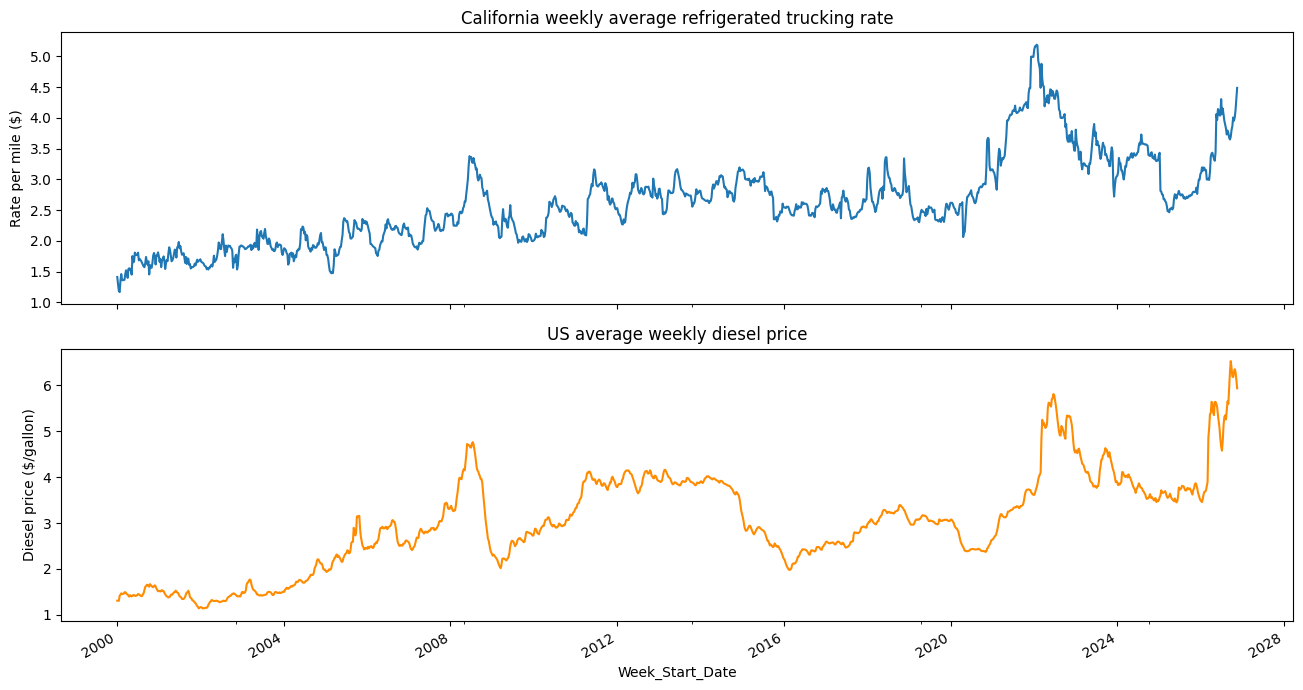

In [4]:
# Causal short-gap handling: carry forward at most two consecutive missing weeks.
# Longer gaps are dropped rather than interpolated from future observations.
ts_data = weekly_raw.ffill(limit=2).dropna().copy()

print("Rows retained:", len(ts_data))
print("Rows removed because of unresolved gaps:", len(weekly_raw) - len(ts_data))
print("Remaining missing values:\n", ts_data.isna().sum())
print("Index frequency:", ts_data.index.freq)

if len(ts_data) < 104:
    raise ValueError("Fewer than 104 weekly observations remain; annual seasonal benchmarks/models need more history.")

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ts_data["Rate Per Mile"].plot(ax=ax[0], title="California weekly average refrigerated trucking rate")
ax[0].set_ylabel("Rate per mile ($)")
ts_data["US_Diesel_Price"].plot(ax=ax[1], color="darkorange", title="US average weekly diesel price")
ax[1].set_ylabel("Diesel price ($/gallon)")
plt.tight_layout()
plt.show()

## 4. Seasonality and stationarity diagnostics

A weekly series can have annual seasonality (approximately 52 weeks). The decomposition uses a 52-week period. The decomposition is descriptive, not proof of a particular economic cause.

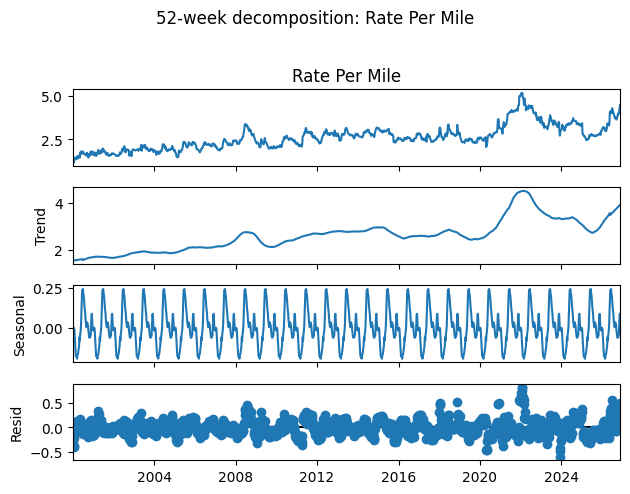

Rate Per Mile: level ADF p=0.18566; first-difference ADF p=0.00000


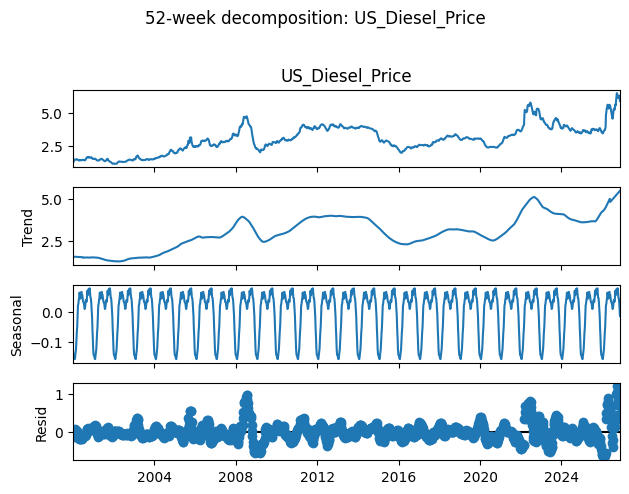

US_Diesel_Price: level ADF p=0.35898; first-difference ADF p=0.00000


In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

for col in ["Rate Per Mile", "US_Diesel_Price"]:
    result = seasonal_decompose(ts_data[col], model="additive", period=52, extrapolate_trend="freq")
    result.plot()
    plt.suptitle(f"52-week decomposition: {col}", y=1.02)
    plt.tight_layout()
    plt.show()

    adf_level = adfuller(ts_data[col].dropna())
    adf_diff = adfuller(ts_data[col].diff().dropna())
    print(f"{col}: level ADF p={adf_level[1]:.5f}; first-difference ADF p={adf_diff[1]:.5f}")

## 5. Chronological train / validation / test split

No random shuffling is used. The validation set is used for model diagnostics and the test set is reserved for the final out-of-sample comparison. Each validation/test forecast is made from a single forecast origin, so predictions do not use actual observations from inside the forecast horizon.

In [6]:
n = len(ts_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = ts_data.iloc[:train_end].copy()
train_val = ts_data.iloc[:val_end].copy()
validation = ts_data.iloc[train_end:val_end].copy()
test = ts_data.iloc[val_end:].copy()

print(f"Train: {len(train)} weeks ({train.index.min().date()} to {train.index.max().date()})")
print(f"Validation: {len(validation)} weeks ({validation.index.min().date()} to {validation.index.max().date()})")
print(f"Test: {len(test)} weeks ({test.index.min().date()} to {test.index.max().date()})")
print("Test horizon:", len(test), "weeks")

Train: 981 weeks (2000-01-03 to 2018-10-22)
Validation: 210 weeks (2018-10-29 to 2022-10-31)
Test: 211 weeks (2022-11-07 to 2026-11-16)
Test horizon: 211 weeks


## 6. Forecasting helpers and common metrics

Seasonal MASE uses a 52-week seasonal-naive denominator. A MASE below 1 means the model beats the seasonal-naive benchmark on average absolute error. All model predictions are aligned to the exact same target dates.

In [7]:
TARGET = "Rate Per Mile"
SEASONAL_PERIOD = 52

def seasonal_naive_forecast(history, horizon, season=SEASONAL_PERIOD):
    values = np.asarray(history, dtype=float)
    if len(values) < season:
        raise ValueError("Not enough history for seasonal naive forecast.")
    # Repeat the latest observed seasonal cycle for any forecast horizon.
    return np.resize(values[-season:], horizon)

def calculate_metrics(y_true, y_pred, y_train):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    seasonal_errors = np.abs(np.asarray(y_train)[SEASONAL_PERIOD:] -
                              np.asarray(y_train)[:-SEASONAL_PERIOD])
    seasonal_scale = np.mean(seasonal_errors)
    mase = mae / seasonal_scale if seasonal_scale > 0 else np.nan
    wmape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))
    return {"MAE": mae, "RMSE": rmse, "Seasonal_MASE": mase, "WMAPE": wmape}

def metric_row(name, actual, predicted, history):
    return {"Model": name, **calculate_metrics(actual, predicted, history)}

## 7. Model 1 — Seasonal Naive (benchmark)

The forecast for each week is the value from 52 weeks earlier. This is an important benchmark because both series showed strong annual seasonality in the original analysis.

In [8]:
val_predictions = {}
test_predictions = {}

val_predictions["Seasonal Naive"] = seasonal_naive_forecast(train[TARGET], len(validation))
test_predictions["Seasonal Naive"] = seasonal_naive_forecast(train_val[TARGET], len(test))

## 8. Model 2 — VAR (rate and diesel jointly)

VAR is fitted to first differences to address non-stationarity. Lag order is selected using AIC from the training data, capped at 8 to avoid an excessively parameter-heavy model. Forecasted differences are cumulatively summed back to levels. Diesel is forecast jointly; actual validation/test diesel values are never passed into the forecast.

In [9]:
def fit_var_forecast(history_df, horizon, maxlags=8):
    diff = history_df[["Rate Per Mile", "US_Diesel_Price"]].diff().dropna()
    max_allowed = min(maxlags, max(1, len(diff)//10))
    model = VAR(diff)
    order_selection = model.select_order(maxlags=max_allowed)
    selected = order_selection.aic
    if selected is None or not np.isfinite(selected):
        selected = 1
    selected = max(1, min(int(selected), max_allowed))
    fitted = model.fit(selected)
    diff_fc = fitted.forecast(y=diff.values[-fitted.k_ar:], steps=horizon)
    levels = history_df[["Rate Per Mile", "US_Diesel_Price"]].iloc[-1].values + np.cumsum(diff_fc, axis=0)
    return pd.DataFrame(levels, columns=["Rate Per Mile", "US_Diesel_Price"]), fitted

var_val_frame, var_val_fit = fit_var_forecast(train, len(validation))
val_predictions["VAR"] = var_val_frame[TARGET].to_numpy()

var_test_frame, var_test_fit = fit_var_forecast(train_val, len(test))
test_predictions["VAR"] = var_test_frame[TARGET].to_numpy()

print("Validation VAR lag:", var_val_fit.k_ar)
print("Final VAR lag:", var_test_fit.k_ar)

Validation VAR lag: 3
Final VAR lag: 7


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


## 9. Model 3 — Prophet

Prophet uses yearly seasonality. Weekly seasonality is disabled because observations are already weekly (one observation per Monday). No diesel regressor is used: future diesel prices are not known at the forecast origin, and using actual future diesel would make the comparison unfair.

In [10]:
if PROPHET_AVAILABLE:
    def prophet_forecast(history, horizon):
        p_df = history[[TARGET]].reset_index().rename(columns={"Week_Start_Date": "ds", TARGET: "y"})
        model = Prophet(
            weekly_seasonality=False,
            yearly_seasonality=True,
            daily_seasonality=False,
            seasonality_mode="additive"
        )
        model.fit(p_df)
        future = model.make_future_dataframe(periods=horizon, freq="W-MON", include_history=False)
        fc = model.predict(future)
        return fc["yhat"].to_numpy(), model

    prophet_val, prophet_val_model = prophet_forecast(train, len(validation))
    val_predictions["Prophet"] = prophet_val
    prophet_test, prophet_final_model = prophet_forecast(train_val, len(test))
    test_predictions["Prophet"] = prophet_test
else:
    print("Prophet skipped: install prophet and rerun this section.")

## 10. Model 4 — XGBoost with recursive autoregressive features

Features contain only past rate observations and deterministic calendar Fourier terms. Forecasts are recursive: after each predicted week, that prediction becomes the lag value for the next week. No actual rate or diesel values from inside validation/test are used.

In [11]:
def fourier_features(dates, origin_date, harmonics=3):
    # Continuous week number from the training origin; annual period is 52.1775 weeks.
    weeks = ((pd.DatetimeIndex(dates) - pd.Timestamp(origin_date)).days / 7.0).to_numpy()
    out = {}
    period = 365.2425 / 7.0
    for k in range(1, harmonics + 1):
        out[f"sin_{k}"] = np.sin(2 * np.pi * k * weeks / period)
        out[f"cos_{k}"] = np.cos(2 * np.pi * k * weeks / period)
    return pd.DataFrame(out, index=pd.DatetimeIndex(dates))

def make_xgb_training_frame(history, lags=52, harmonics=3):
    y = history[TARGET]
    X = fourier_features(history.index, history.index[0], harmonics)
    for lag in range(1, lags + 1):
        X[f"lag_{lag}"] = y.shift(lag)
    frame = X.copy()
    frame["y"] = y
    return frame.dropna()

def xgb_recursive_forecast(history, future_dates, lags=52, harmonics=3):
    if not XGBOOST_AVAILABLE:
        raise ImportError("Install xgboost to run this model.")
    frame = make_xgb_training_frame(history, lags=lags, harmonics=harmonics)
    X_train, y_train = frame.drop(columns="y"), frame["y"]
    model = XGBRegressor(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="reg:squarederror",
        reg_lambda=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    history_values = list(history[TARGET].astype(float).values)
    preds = []
    calendar = fourier_features(future_dates, history.index[0], harmonics)
    for i, date in enumerate(future_dates):
        row = calendar.iloc[i].to_dict()
        for lag in range(1, lags + 1):
            row[f"lag_{lag}"] = history_values[-lag]
        row_df = pd.DataFrame([row], columns=X_train.columns)
        pred = float(model.predict(row_df)[0])
        preds.append(pred)
        history_values.append(pred)
    return np.asarray(preds), model

if XGBOOST_AVAILABLE:
    xgb_val, xgb_val_model = xgb_recursive_forecast(train, validation.index)
    val_predictions["XGBoost"] = xgb_val
    xgb_test, xgb_final_model = xgb_recursive_forecast(train_val, test.index)
    test_predictions["XGBoost"] = xgb_test
else:
    print("XGBoost skipped: install xgboost and rerun this section.")

## 11. Model 5 — SARIMAX

A standard non-seasonal ARIMA-style SARIMAX model is included as a baseline. It is univariate and therefore does not require future diesel prices.

In [13]:
def sarimax_forecast(history, horizon, order=(1, 1, 1), seasonal_order=(0, 0, 0, 0), exog=None):
    # Strip the datetime index to prevent statsmodels from complaining about missing frequency
    endog = history[TARGET].values
    model = SARIMAX(
        endog,
        order=order,
        seasonal_order=seasonal_order,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fitted = model.fit(disp=False)
    forecast = fitted.get_forecast(steps=horizon).predicted_mean
    return np.asarray(forecast), fitted

sarimax_val, sarimax_val_fit = sarimax_forecast(train, len(validation))
val_predictions["SARIMAX"] = sarimax_val
sarimax_test, sarimax_final_fit = sarimax_forecast(train_val, len(test))
test_predictions["SARIMAX"] = sarimax_test

## 12. Model 6 — Fourier terms + SARIMAX

Fourier terms represent smooth annual seasonality, while SARIMAX captures short-term autocorrelation and differencing. Fourier terms are deterministic calendar inputs, so they are known throughout the forecast horizon and do not leak target information.

In [16]:
def make_fourier_exog(dates, origin_date, harmonics=3):
    return fourier_features(dates, origin_date, harmonics=harmonics)

def fourier_sarimax_forecast(history, future_dates, harmonics=3, order=(1, 1, 1)):
    exog_train = make_fourier_exog(history.index, history.index[0], harmonics)
    exog_future = make_fourier_exog(future_dates, history.index[0], harmonics)

    # Strip pandas index from both target (endog) and features (exog) to prevent statsmodels frequency errors
    endog = history[TARGET].values
    exog_train_np = exog_train.values
    exog_future_np = exog_future.values

    model = SARIMAX(
        endog,
        exog=exog_train_np,
        order=order,
        seasonal_order=(0, 0, 0, 0),
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fitted = model.fit(disp=False)
    fc = fitted.get_forecast(steps=len(future_dates), exog=exog_future_np).predicted_mean
    return np.asarray(fc), fitted

fourier_val, fourier_val_fit = fourier_sarimax_forecast(train, validation.index)
val_predictions["Fourier + SARIMAX"] = fourier_val
fourier_test, fourier_final_fit = fourier_sarimax_forecast(train_val, test.index)
test_predictions["Fourier + SARIMAX"] = fourier_test

## 13. Validation comparison

Validation forecasts are produced from the end of the training period, without updating the models using validation observations. This is the appropriate validation setup for a fixed-origin multi-week forecast.

In [17]:
validation_rows = []
for name, pred in val_predictions.items():
    validation_rows.append(metric_row(name, validation[TARGET].values, pred, train[TARGET].values))
validation_comparison = pd.DataFrame(validation_rows).set_index("Model").sort_values("RMSE")
display(validation_comparison)

,MAE,RMSE,Seasonal_MASE,WMAPE
Model,,,,
VAR,0.683307,0.892878,2.915099,0.206320
Seasonal Naive,0.783478,1.006771,3.342446,0.236566
XGBoost,0.763838,1.007151,3.258658,0.230636
Fourier + SARIMAX,0.772495,1.020516,3.295589,0.233250
SARIMAX,0.778691,1.044379,3.322023,0.235121
Prophet,0.852906,1.165217,3.638638,0.257530


## 14. Final held-out test comparison

All final test forecasts were generated from the end of the combined training + validation period. Each algorithm has the same test horizon and the same information boundary. The test metrics are calculated once, after the forecasting choices have been fixed.

In [18]:
test_rows = []
for name, pred in test_predictions.items():
    if len(pred) != len(test):
        raise ValueError(f"{name} prediction length {len(pred)} does not match test length {len(test)}")
    test_rows.append(metric_row(name, test[TARGET].values, pred, train_val[TARGET].values))

final_comparison = pd.DataFrame(test_rows).set_index("Model").sort_values("RMSE")
display(final_comparison.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "Seasonal_MASE": "{:.3f}",
    "WMAPE": "{:.2%}"
}))

best_model = final_comparison["RMSE"].idxmin()
print(f"Best model on the held-out test set by RMSE: {best_model}")
print("Interpretation: also inspect MAE and Seasonal_MASE; a single metric should not determine the conclusion.")

,MAE,RMSE,Seasonal_MASE,WMAPE
Model,,,,
SARIMAX,0.4292,0.5305,1.380,13.04%
Fourier + SARIMAX,0.4312,0.5372,1.386,13.11%
VAR,0.6267,0.7539,2.015,19.05%
XGBoost,1.0628,1.1868,3.417,32.30%
Seasonal Naive,1.1480,1.3025,3.691,34.89%
Prophet,1.7446,1.8509,5.609,53.03%


Best model on the held-out test set by RMSE: SARIMAX
Interpretation: also inspect MAE and Seasonal_MASE; a single metric should not determine the conclusion.


## 15. Actual vs predicted plots

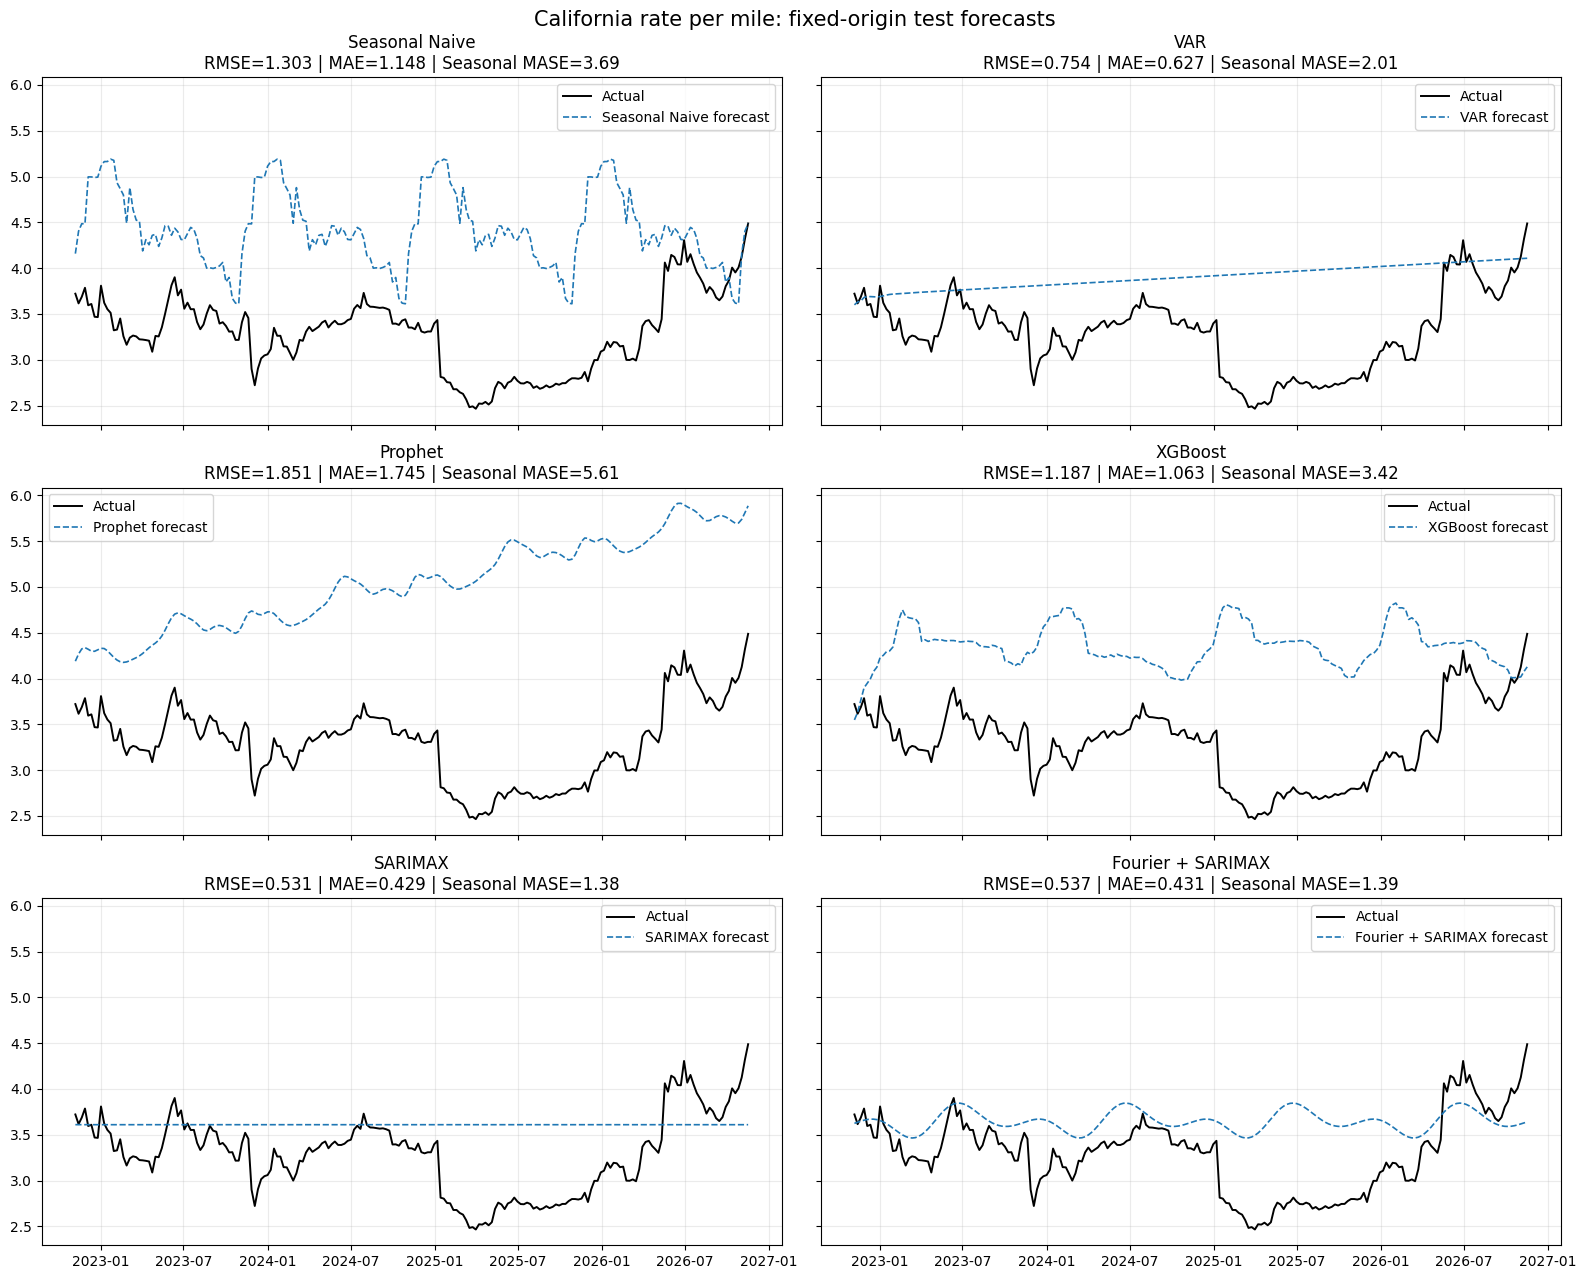

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(16, 13), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (name, pred) in zip(axes, test_predictions.items()):
    ax.plot(test.index, test[TARGET], label="Actual", color="black", linewidth=1.4)
    ax.plot(test.index, pred, label=f"{name} forecast", linestyle="--", linewidth=1.2)
    row = final_comparison.loc[name]
    ax.set_title(f"{name}\nRMSE={row['RMSE']:.3f} | MAE={row['MAE']:.3f} | Seasonal MASE={row['Seasonal_MASE']:.2f}")
    ax.grid(alpha=0.25)
    ax.legend()

for ax in axes[len(test_predictions):]:
    ax.axis("off")

plt.suptitle("California rate per mile: fixed-origin test forecasts", fontsize=15)
plt.tight_layout()
plt.show()

## 16. Residual checks for the best test-ranked model

The following plot is a visual check, not a substitute for a full residual diagnostic. Forecast residuals over a long fixed horizon can show systematic drift, seasonality, or regime changes.

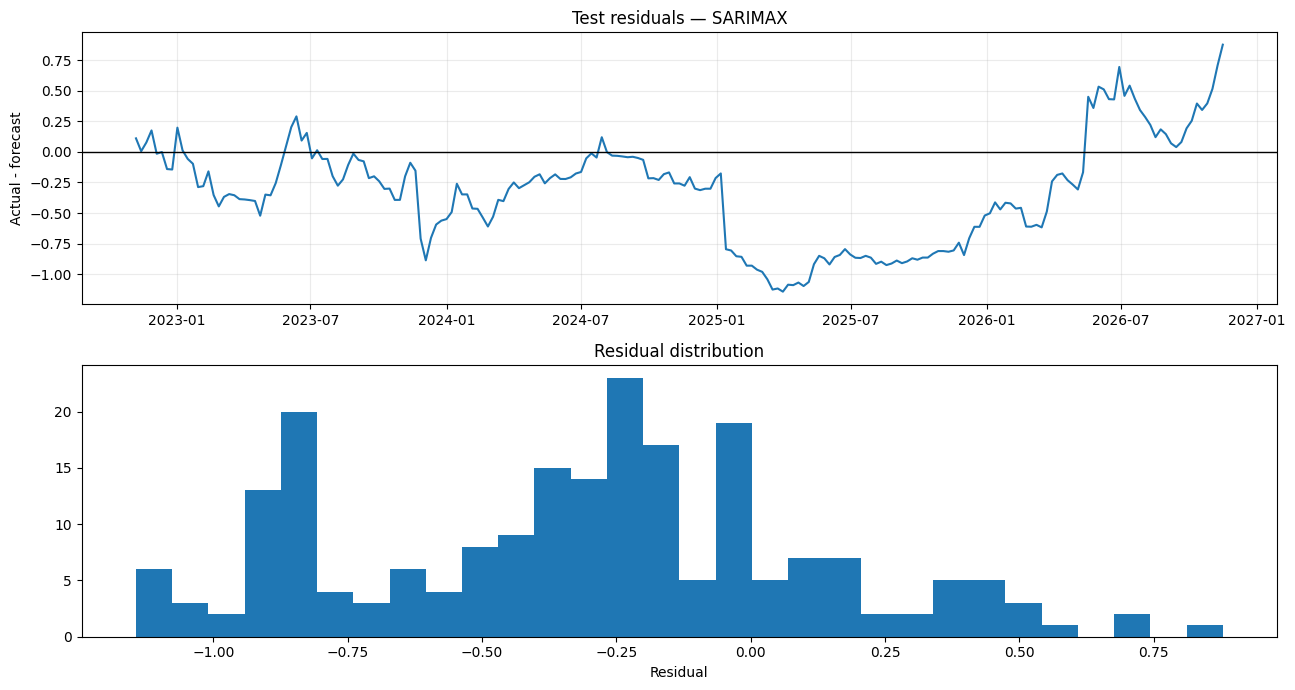

In [20]:
best_predictions = test_predictions[best_model]
residuals = test[TARGET].to_numpy() - np.asarray(best_predictions)

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].plot(test.index, residuals)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title(f"Test residuals — {best_model}")
axes[0].set_ylabel("Actual - forecast")
axes[0].grid(alpha=0.25)

axes[1].hist(residuals, bins=30)
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Residual")
plt.tight_layout()
plt.show()

## 17. Optional future forecast using the selected model

This section forecasts the next 12 weeks from all available California data. It uses the model family that ranked best on the held-out test set. This is a model-selection convenience, not a guarantee that the model will remain best in the future.

For VAR, the joint diesel/rate forecast is used. For other models, the rate forecast is univariate. The future date index is explicitly Monday-based (`W-MON`).

,Forecast_Rate_Per_Mile
Week_Start_Date,
2026-11-23,4.499821
2026-11-30,4.500939
2026-12-07,4.501047
2026-12-14,4.501057
2026-12-21,4.501058
2026-12-28,4.501058
2027-01-04,4.501058
2027-01-11,4.501058
2027-01-18,4.501058


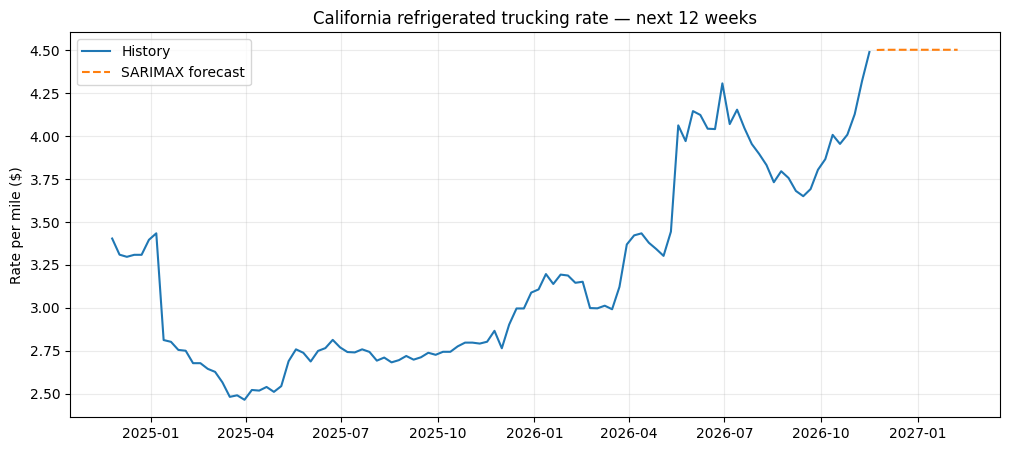

In [21]:
future_horizon = 12
future_dates = pd.date_range(
    start=ts_data.index[-1] + pd.Timedelta(weeks=1),
    periods=future_horizon,
    freq="W-MON"
)

if best_model == "Seasonal Naive":
    future_rate = seasonal_naive_forecast(ts_data[TARGET], future_horizon)
elif best_model == "VAR":
    future_frame, _ = fit_var_forecast(ts_data, future_horizon)
    future_rate = future_frame[TARGET].to_numpy()
elif best_model == "Prophet" and PROPHET_AVAILABLE:
    future_rate, _ = prophet_forecast(ts_data, future_horizon)
elif best_model == "XGBoost" and XGBOOST_AVAILABLE:
    future_rate, _ = xgb_recursive_forecast(ts_data, future_dates)
elif best_model == "SARIMAX":
    future_rate, _ = sarimax_forecast(ts_data, future_horizon)
else:
    future_rate, _ = fourier_sarimax_forecast(ts_data, future_dates)

future_forecast = pd.DataFrame({"Forecast_Rate_Per_Mile": future_rate}, index=future_dates)
future_forecast.index.name = "Week_Start_Date"
display(future_forecast)

plt.figure(figsize=(12, 5))
plt.plot(ts_data.index[-104:], ts_data[TARGET].tail(104), label="History")
plt.plot(future_forecast.index, future_forecast["Forecast_Rate_Per_Mile"], "--", label=f"{best_model} forecast")
plt.title("California refrigerated trucking rate — next 12 weeks")
plt.ylabel("Rate per mile ($)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 18. Methodological notes and limitations

- **California only:** the Region filter is applied before weekly aggregation. This is a California statewide average across the available California records/routes, not a route-specific forecast.
- **No future-data leakage:** no actual validation/test diesel prices or trucking rates are supplied to any model after the forecast origin. XGBoost forecasts recursively rather than using actual within-test lags.
- **Comparable forecast task:** all models make a fixed-origin forecast over the same validation and test dates. This is intentionally different from rolling one-step evaluation.
- **Missing weeks:** only short gaps are forward-filled, using past observations only. Long unresolved gaps are dropped. Check the printed gap counts because dropping weeks means the remaining index may no longer be perfectly regular.
- **Diesel scope:** the EIA series is US average diesel, not California diesel. VAR uses its historical values and jointly forecasts it.
- **Seasonality:** a 52-week benchmark and Fourier annual terms are used. Calendar years contain about 52.18 weeks, so the seasonal-naive benchmark is a practical weekly approximation.
- **Model uncertainty:** this notebook compares point forecasts. It does not claim calibrated prediction intervals.
- **Robustness:** for a stronger research result, repeat the evaluation with rolling-origin backtesting and report the distribution of errors across several origins.